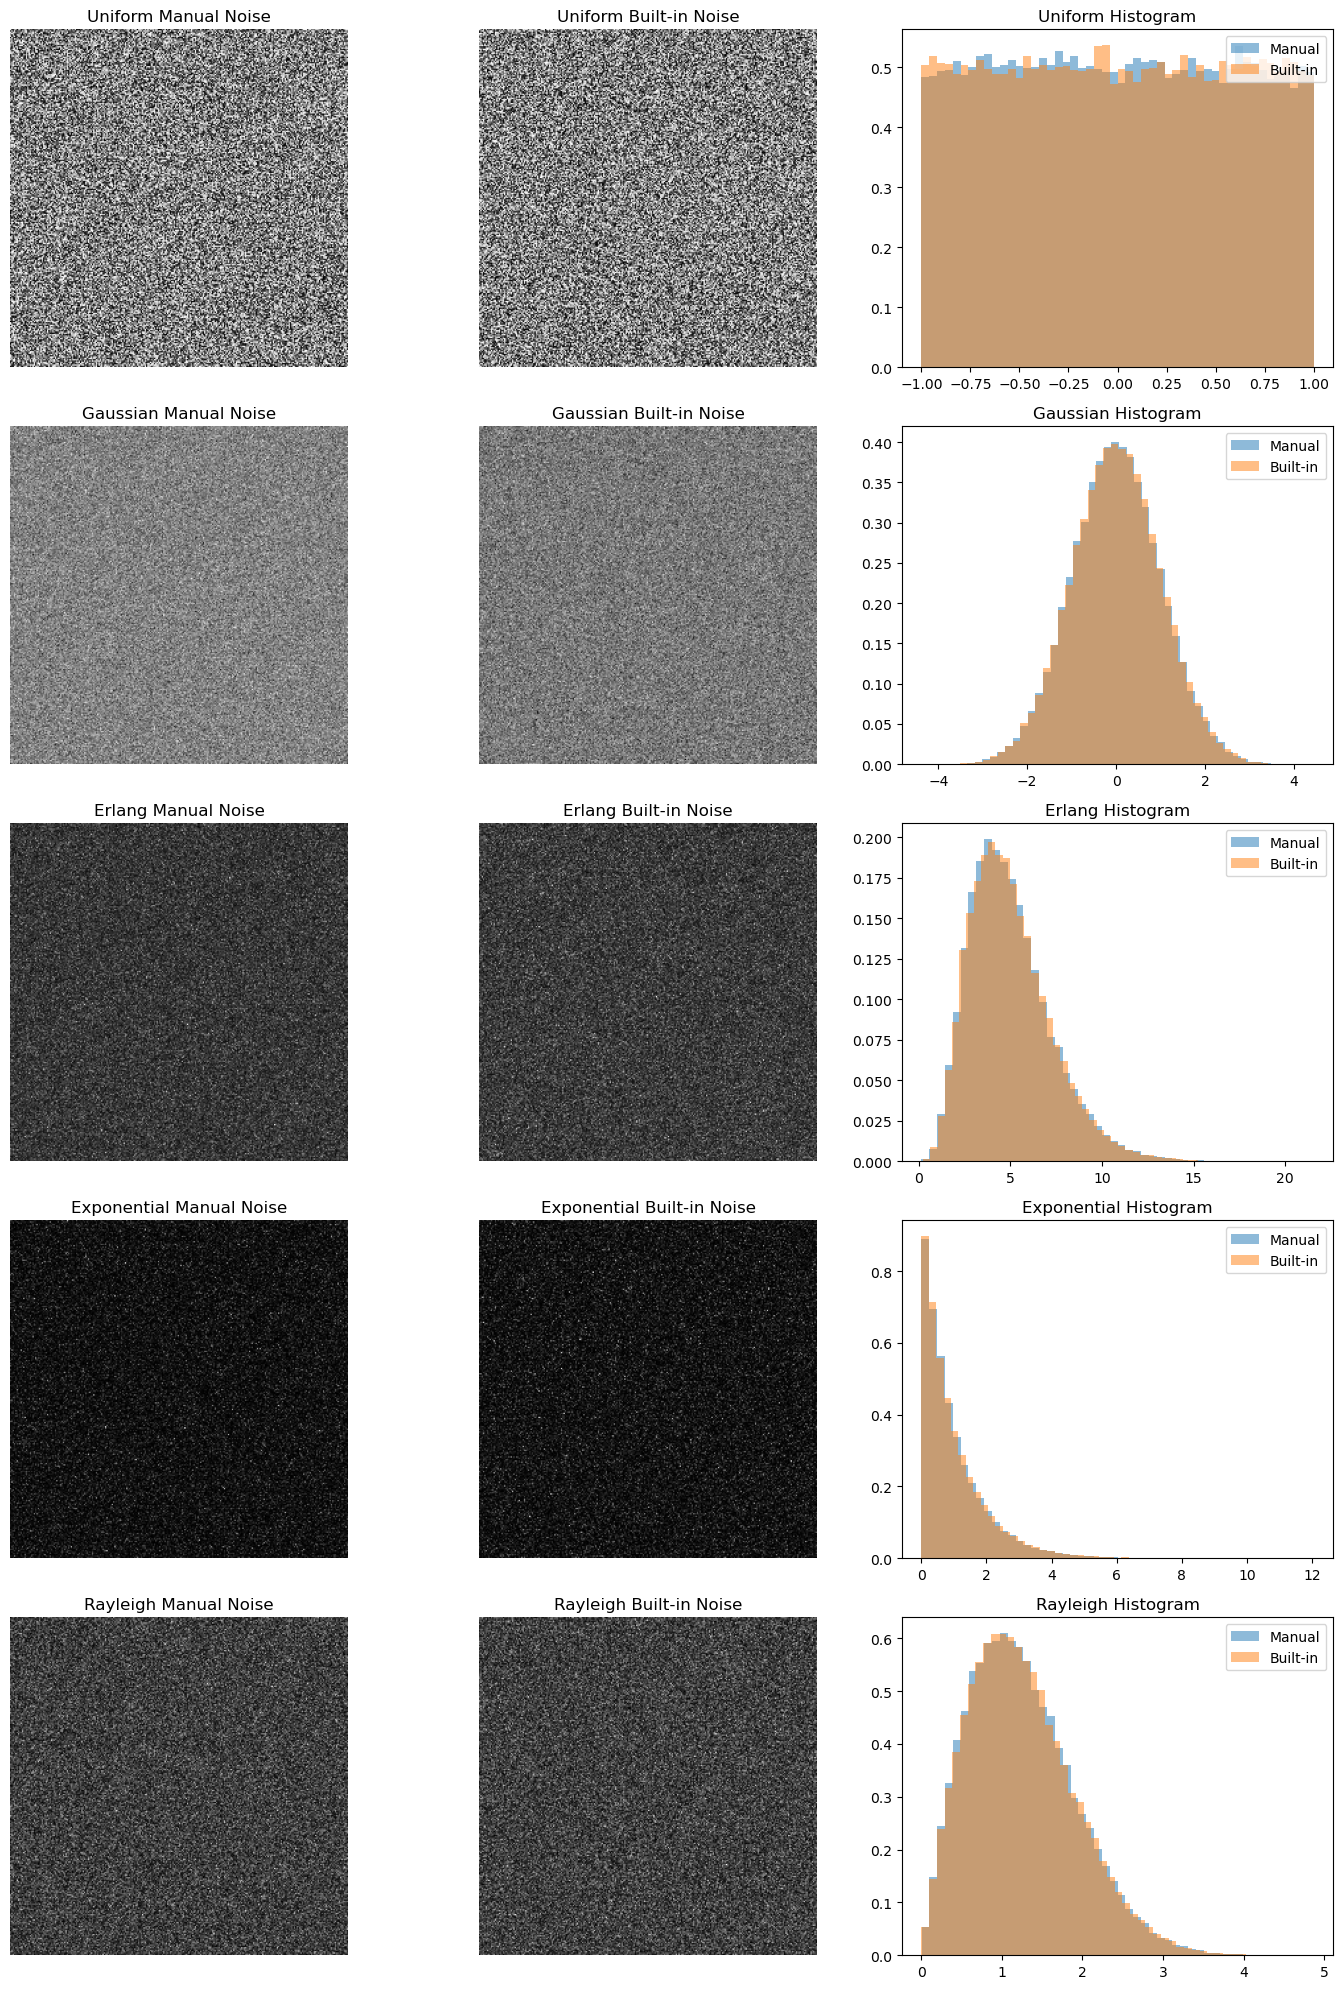

In [1]:
#Write a program to generate following noises using equations derived from PDFs of noise distributions. Compare your output with those 
#generated using inbuilt function imnoise. Plot the histograms of generated noise to determine the shape of the distribution.  
 
import numpy as np
import matplotlib.pyplot as plt
import math

# Number of noise samples
N = 256 * 256

# 1. Uniform Noise
a = -1
b = 1

u = np.random.random(N)
uniform_manual = a + (b - a) * u
uniform_builtin = np.random.uniform(a, b, N)


# 2. Gaussian Noise
mu = 0
sigma = 1

u1 = np.random.random(N)
u2 = np.random.random(N)

# Box-Muller equation
gaussian_manual = mu + sigma * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_builtin = np.random.normal(mu, sigma, N)


# 3. Erlang Noise
k = 5
lam = 1

# Sum of k independent exponential random variables
erlang_manual = np.zeros(N)

for i in range(k):
    u = np.random.random(N)
    erlang_manual += -np.log(u) / lam

erlang_builtin = np.random.gamma(k, 1 / lam, N)


# 4. Exponential Noise
lam = 1

u = np.random.random(N)
exponential_manual = -np.log(1 - u) / lam
exponential_builtin = np.random.exponential(1 / lam, N)


# 5. Rayleigh Noise
sigma = 1

u = np.random.random(N)
rayleigh_manual = sigma * np.sqrt(-2 * np.log(1 - u))
rayleigh_builtin = np.random.rayleigh(sigma, N)


# Store all noise distributions
noise_data = [
    ("Uniform", uniform_manual, uniform_builtin),
    ("Gaussian", gaussian_manual, gaussian_builtin),
    ("Erlang", erlang_manual, erlang_builtin),
    ("Exponential", exponential_manual, exponential_builtin),
    ("Rayleigh", rayleigh_manual, rayleigh_builtin)
]


# Display noise images and histograms
plt.figure(figsize=(14, 20))

for i, (name, manual, builtin) in enumerate(noise_data):

    # Display manually generated noise
    plt.subplot(5, 3, 3*i + 1)
    plt.imshow(manual.reshape(256, 256), cmap='gray')
    plt.title(name + " Manual Noise")
    plt.axis("off")

    # Display built-in generated noise
    plt.subplot(5, 3, 3*i + 2)
    plt.imshow(builtin.reshape(256, 256), cmap='gray')
    plt.title(name + " Built-in Noise")
    plt.axis("off")

    # Plot histograms
    plt.subplot(5, 3, 3*i + 3)
    plt.hist(manual, bins=50, density=True,
             alpha=0.5, label='Manual')
    plt.hist(builtin, bins=50, density=True,
             alpha=0.5, label='Built-in')

    plt.title(name + " Histogram")
    plt.legend()

plt.tight_layout()
plt.show()
